In [1]:
import pandas as pd

chemin_no2 = "../../data/raw/geodair/no2_paris_a1_01_2015_11_2026.csv"
apercu = pd.read_csv(chemin_no2, sep=";", nrows=5)
apercu

,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude
0,2015-01-01 00:00:00,2015-01-01 01:00:00,AIRPARIF,FR04A01,ILE-DE-FRANCE-PARIS,FR04004,PARIS 18eme,Urbaine,NO2,Fond,...,122.0,122.00,µg-m3,NaN,NaN,NaN,A,1,48.891666,2.346667
1,2015-01-01 01:00:00,2015-01-01 02:00:00,AIRPARIF,FR04A01,ILE-DE-FRANCE-PARIS,FR04004,PARIS 18eme,Urbaine,NO2,Fond,...,130.0,130.00,µg-m3,NaN,NaN,NaN,A,1,48.891666,2.346667
2,2015-01-01 02:00:00,2015-01-01 03:00:00,AIRPARIF,FR04A01,ILE-DE-FRANCE-PARIS,FR04004,PARIS 18eme,Urbaine,NO2,Fond,...,119.3,119.25,µg-m3,NaN,NaN,NaN,A,1,48.891666,2.346667
3,2015-01-01 03:00:00,2015-01-01 04:00:00,AIRPARIF,FR04A01,ILE-DE-FRANCE-PARIS,FR04004,PARIS 18eme,Urbaine,NO2,Fond,...,125.5,125.50,µg-m3,NaN,NaN,NaN,A,1,48.891666,2.346667
4,2015-01-01 04:00:00,2015-01-01 05:00:00,AIRPARIF,FR04A01,ILE-DE-FRANCE-PARIS,FR04004,PARIS 18eme,Urbaine,NO2,Fond,...,109.8,109.75,µg-m3,NaN,NaN,NaN,A,1,48.891666,2.346667


In [2]:
apercu.iloc[0]

Date de début                2015-01-01 00:00:00
Date de fin                  2015-01-01 01:00:00
Organisme                               AIRPARIF
code zas                                 FR04A01
Zas                          ILE-DE-FRANCE-PARIS
code site                                FR04004
nom site                             PARIS 18eme
type d'implantation                      Urbaine
Polluant                                     NO2
type d'influence                            Fond
Réglementaire                                Oui
type d'évaluation                  mesures fixes
type de valeur           moyenne horaire validée
valeur                                     122.0
valeur brute                               122.0
unité de mesure                            µg-m3
taux de saisie                               NaN
couverture temporelle                        NaN
couverture de données                        NaN
code qualité                                   A
validité            

In [3]:
colonnes = ["Date de début", "code site", "nom site", "type d'influence", "valeur", "validité"]
no2 = pd.read_csv(chemin_no2, sep=";", usecols=colonnes)
no2.shape

(1392600, 6)

In [4]:
no2.groupby(["code site", "nom site", "type d'influence"]).size()

code site  nom site              type d'influence
FR04004    PARIS 18eme           Fond                104136
FR04012    Place Victor Basch    Trafic               81096
FR04014    PARIS 12eme           Fond                104280
FR04031    Av Champs Elysees     Trafic              103848
FR04037    PARIS 13eme           Fond                104232
FR04055    PARIS 1er Les Halles  Fond                 62568
FR04060    PARIS 7eme            Fond                104232
FR04071    Rue Bonaparte         Trafic              104160
FR04118    Place de l'Opéra      Trafic              103680
FR04131    Boulevard Haussmann   Trafic              104280
FR04135    Boulevard Soult       Trafic               71592
FR04141    Quai des Celestins    Trafic              104136
FR04143    PARIS Centre          Fond                 41424
FR04179    PARIS Stade Lenglen   Fond                 94776
FR04329    Bld peripherique Est  Trafic              104160
dtype: int64

In [5]:
chemin_pm25 = "../../data/raw/geodair/pm25_paris_a1_01_2015_11_2026.csv"
pm25 = pd.read_csv(chemin_pm25, sep=";", usecols=colonnes)
pm25.groupby(["code site", "nom site", "type d'influence"]).size()

code site  nom site              type d'influence
FR04004    PARIS 18eme           Fond                 42912
FR04031    Av Champs Elysees     Trafic               34368
FR04055    PARIS 1er Les Halles  Fond                 62592
FR04131    Boulevard Haussmann   Trafic               42912
FR04143    PARIS Centre          Fond                 41424
FR04329    Bld peripherique Est  Trafic              104160
dtype: int64

In [6]:
pm25.groupby("nom site")["Date de début"].agg(["min", "max"])

,min,max
nom site,,
Av Champs Elysees,2022-12-23 00:00:00,2026-11-23 23:00:00
Bld peripherique Est,2015-01-01 00:00:00,2026-11-23 23:00:00
Boulevard Haussmann,2022-01-01 00:00:00,2026-11-23 23:00:00
PARIS 18eme,2022-01-01 00:00:00,2026-11-23 23:00:00
PARIS 1er Les Halles,2019-09-25 00:00:00,2026-11-23 23:00:00
PARIS Centre,2015-01-01 00:00:00,2019-09-22 23:00:00


In [7]:
fond_pm25 = pm25[pm25["type d'influence"] == "Fond"]
depuis_2022 = fond_pm25[fond_pm25["Date de début"] >= "2022-01-01"]
comparaison = depuis_2022.pivot_table(index="Date de début", columns="nom site", values="valeur")
comparaison.describe()

nom site,PARIS 18eme,PARIS 1er Les Halles
count,40164.000000,42173.000000
mean,9.762830,10.974140
std,7.934177,7.919891
min,-2.900000,0.300000
25%,4.800000,5.900000
50%,7.700000,8.700000
75%,12.300000,13.500000
max,109.600000,111.100000


In [8]:
# Panne de capteur, pour enlever les mesures prises par des capteurs défectueux
# 1 mesure correcte, -1 capteurs en panne
print(no2["validité"].value_counts())
print(pm25["validité"].value_counts())

validité
 1    1338304
-1      54296
Name: count, dtype: int64
validité
 1    314471
-1     13897
Name: count, dtype: int64


In [9]:
# Fonction pour garder que les mesures valides
def nettoyer(df, stations):
    df = df[df["code site"].isin(stations)]
    df = df[(df["validité"] == 1) & (df["valeur"] >= 0)]
    df = df.assign(date=pd.to_datetime(df["Date de début"]))
    return df.groupby("date")["valeur"].mean()

In [10]:
stations_no2 = ["FR04004", "FR04014", "FR04037", "FR04060"]
stations_pm25 = ["FR04004", "FR04055", "FR04143"]

no2_horaire = nettoyer(no2, stations_no2)
pm25_horaire = nettoyer(pm25, stations_pm25)

print(no2_horaire.shape, pm25_horaire.shape)

(104280,) (98348,)


In [11]:
no2_jour = no2_horaire.resample("D").mean()
pm25_jour = pm25_horaire.resample("D").mean()

print(no2_jour.isna().sum(), pm25_jour.isna().sum())

0 143


<Axes: title={'center': 'PM2.5 - moyenne journalière, stations de fond Paris'}, xlabel='date'>

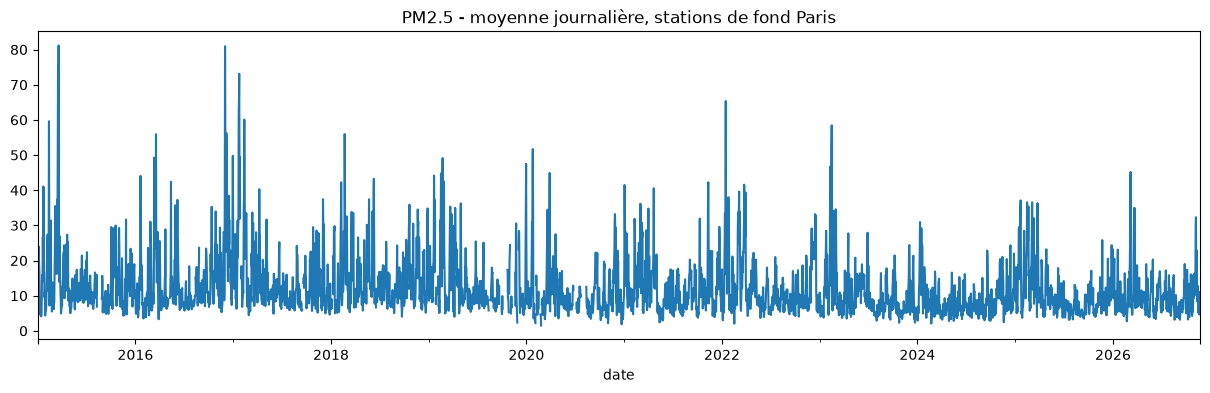

In [12]:
pm25_jour.plot(figsize=(15, 4), title="PM2.5 - moyenne journalière, stations de fond Paris")

In [13]:
# Nombre de jours sans aucune mesure par années
# 2019 a bcp de valeur manquante car il s'agit d'une année avec chg de station
pm25_jour[pm25_jour.isna()].index.year.value_counts().sort_index()

date
2015    18
2016     8
2017    13
2018     7
2019    59
2020    37
2021     1
Name: count, dtype: int64

<Axes: title={'center': 'NO2 - moyenne journalière, stations de fond Paris'}, xlabel='date'>

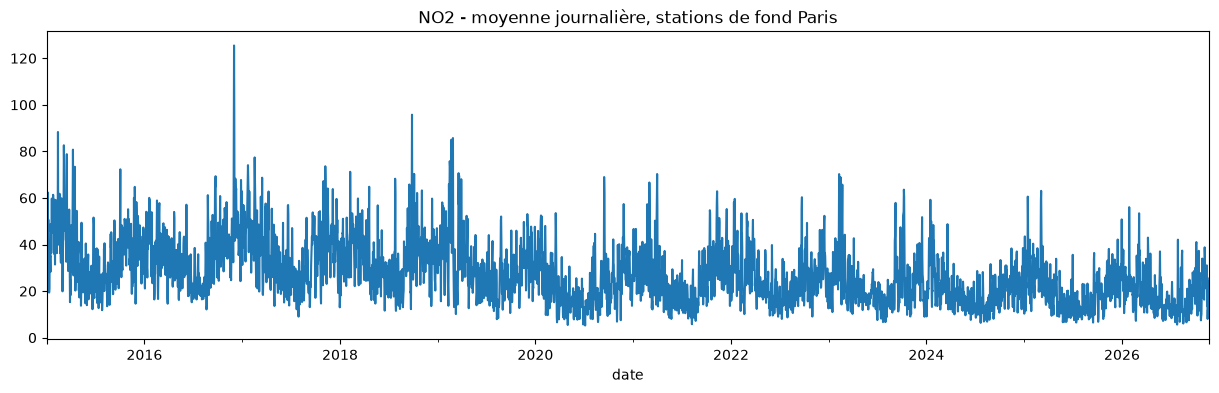

In [14]:
no2_jour.plot(figsize=(15, 4), title="NO2 - moyenne journalière, stations de fond Paris")


In [15]:
from prophet import Prophet

df_no2 = no2_jour.reset_index()
df_no2.columns = ["ds", "y"]

train = df_no2[df_no2["ds"] < "2025-01-01"] # train 2016 - 2024
test = df_no2[df_no2["ds"] >= "2025-01-01"] # test 2024 - 2026

modele = Prophet()
modele.fit(train)
prevision = modele.predict(test[["ds"]])

Importing plotly failed. Interactive plots will not work.
/home/bleam/code/jedha/air-quality-prediction/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
17:48:16 - cmdstanpy - INFO - Chain [1] start processing
17:48:16 - cmdstanpy - INFO - Chain [1] done processing


In [16]:
import numpy as np

# erreur moyenne
mae_prophet = np.abs(test["y"].values - prevision["yhat"].values).mean()

# Baseline persistance, si la prédiction de j+1 reprend la valeur de la veille
hier = df_no2["y"].shift(1)[df_no2["ds"] >= "2025-01-01"]
mae_persistance = np.abs(test["y"].values - hier.values).mean()

print("Prophet :", round(mae_prophet, 2), "| Persistance :", round(mae_persistance, 2))
print("Donc prophet fait moins bien que la baseline")

Prophet : 6.25 | Persistance : 5.71
Donc prophet fait moins bien que la baseline


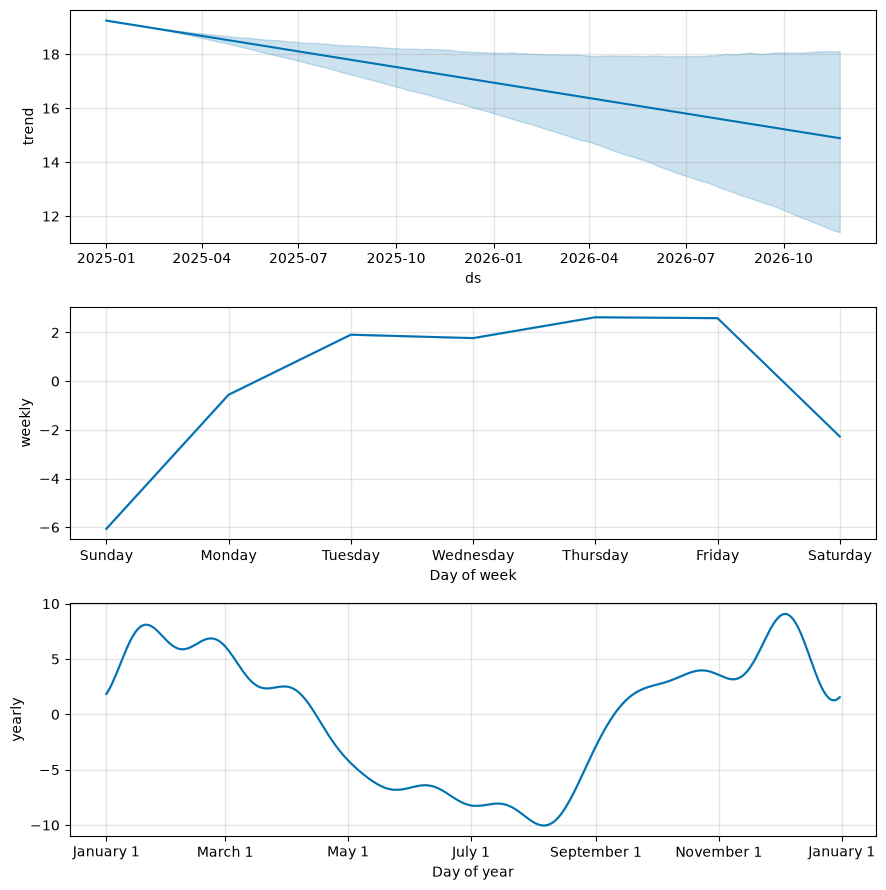

In [17]:
# Prophet NO2
modele.plot_components(prevision);

In [18]:
#
def evaluer(serie):
    df = serie.reset_index()
    df.columns = ["ds", "y"]
    train = df[df["ds"] < "2025-01-01"]
    test = df[df["ds"] >= "2025-01-01"]

    modele = Prophet().fit(train)
    prevision = modele.predict(test[["ds"]])

    mae_prophet = np.nanmean(np.abs(test["y"].values - prevision["yhat"].values))
    hier = df["y"].shift(1)[df["ds"] >= "2025-01-01"]
    mae_persistance = np.nanmean(np.abs(test["y"].values - hier.values))

    print("Prophet :", round(mae_prophet, 2), "| Persistance :", round(mae_persistance, 2))
    return modele, prevision

17:48:18 - cmdstanpy - INFO - Chain [1] start processing
17:48:18 - cmdstanpy - INFO - Chain [1] done processing


Prophet : 4.68 | Persistance : 3.13


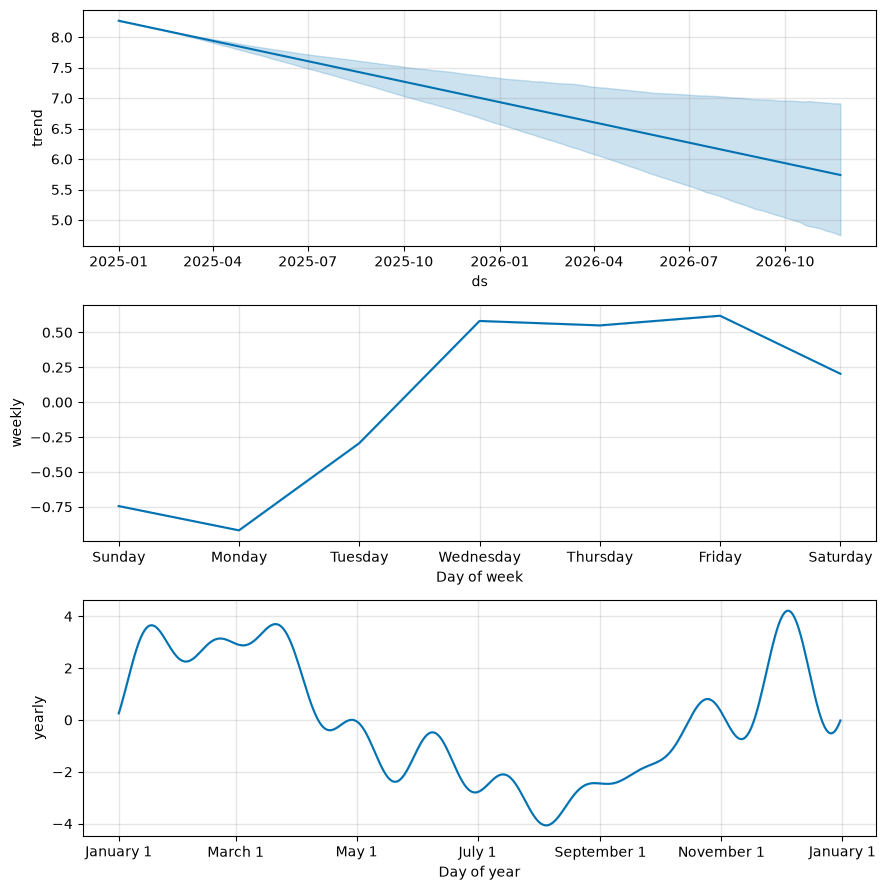

In [19]:
modele_pm25, prevision_pm25 = evaluer(pm25_jour)

# Prophet PM2.5
modele_pm25.plot_components(prevision_pm25);

## Conclusions
- Stations :
  - NO2 : prise des moyenne des stations de fond (18e, 12e, 13e, 7e)
  - PM2.5 :
    - 2015 à sept 2019: Paris Centre
    - oct 2019 à 2022 : Les Halles
    - 2022 à 2024 : Les Halles + 18e
- Données de test: 2024 à 2026 sur les stations Les Halles + 18e
- Nettoyage :
  - On a gardé que les valeurs valide (validité = 1),
  - On a recalculé les moyenne journalières à partir des moyennes horaires
- Split temporel : train 2015-2024, test 2025-2026
- MAE NO2 : Prophet 6.25 vs persistance 5.71 (écart de 0.50)
- MAE PM2.5 : Prophet 4.68 vs persistance 3.13 (écart 1.8)
- ! Prophet est moins bon que la baseline persistance
- On constate également que le calendrier explique bien le NO2 (majorité traffic, diesel), mal les PM2.5 (traffic usure pneus+frein, chauffage bois/fuel, agriculture et méto/vent)
  - Hypothèse: la météo peut améliorer les prédiction pour les PM2.5
  - Le NO2


In [20]:
# Mesure de corrélation entre les stations de fonds et les stations du périphérique
# Plus la corrélation est élevée, plus les taux mesurés sont proches, donc moins le traffic aurait d'influence

trafic_pm25 = nettoyer(pm25, ["FR04329"]).resample("D").mean()
trafic_no2 = nettoyer(no2, ["FR04329"]).resample("D").mean()

print("PM2.5 | corrélation :", round(pm25_jour.corr(trafic_pm25), 2), "| fond :", round(pm25_jour.mean(), 1), "| trafic :", round(trafic_pm25.mean(), 1))

print("NO2   | corrélation :", round(no2_jour.corr(trafic_no2), 2), "| fond :", round(no2_jour.mean(), 1), "| trafic :", round(trafic_no2.mean(), 1))

PM2.5 | corrélation : 0.93 | fond : 12.1 | trafic : 14.7
NO2   | corrélation : 0.74 | fond : 27.3 | trafic : 54.0


## Test propagation : fond vs trafic (périph' Est FR04329)
| | Corrélation fond/trafic | Fond | Trafic | Surplus trafic |
|---|---|---|---|---|
| PM2.5 | 0.93 | 12.1 | 14.7 | +21 % |
| NO2 | 0.74 | 27.3 | 54.0 | x2 |


- PM2.5 : les taux mesurés sur les stations de fond et de trafic sont quasi identiques
  - comportement de pollution régionale, le trafic n'ajoute qu'un petit surplus local

- NO2 : les taux mesurés sur les stations de traffic est 2 fois plus élevé que les stations de fond
  - pollution locale

- Limite : une forte corrélation peut aussi venir de la météo commune aux deux stations. Pour prouver la propagation, il faudra des stations rurales et la direction du vent

- Conséquence pour le modèle : les PM2.5 dépendent de phénomènes à grande échelle (météo, masses d'air)
  - features météo prioritaires, dont la direction du vent